# 03 Model comparison (training set only)

Steps 3-6 of the project workflow: build leakage-free pipelines, cross-validate every candidate on the same folds, select one winner. The test set is not loaded in this notebook.

## Decisions fixed before looking at any results

**Application.** A Vinho Verde producer pre-screens white wine batches before paying for an expert tasting panel. Positive = good wine (quality 7 or above).
- False positive: a mediocre batch is sent to the panel, wasting one tasting ($c_{FP} = 1$).
- False negative: a good batch is never tasted and is sold at the standard price, losing the premium margin. We take $c_{FN} = 3$ as the base case. `04_cost_threshold.ipynb` checks how sensitive the conclusions are to this ratio.

**Folds.** `StratifiedKFold(n_splits=10, shuffle=True, random_state=2026)`, the same folds for every candidate.

**CV metric for selection: PR-AUC (average precision).** About 21% of wines are good. PR-AUC measures how well a model ranks the rare good wines at the top, and unlike ROC-AUC it is not flattered by the many easy negatives. The no-skill baseline is the share of good wines, about 0.21. ROC-AUC, sensitivity, specificity and confusion matrices are reported for every model as supporting evidence.

**Thresholds in the comparison table.** The default 0.5, and the theoretical cost-optimal threshold $t^* = c_{FP}/(c_{FP}+c_{FN}) = 0.25$ for the base case (Lesson 5, Section 7.2). Neither is tuned here. The operating point is chosen in notebook 04.

**Candidates.**
1. Logistic regression, all 11 predictors, unpenalised
2. L1-penalised logistic regression with polynomial degree in {1, 2} and $C = 1/\lambda$ chosen by inner 5-fold CV (one-SE rule, see `wine_utils.OneSELassoLogit`). It must keep at least 5 of the 11 original predictors: if the one-SE choice keeps fewer, we step to the next weaker penalty.
3. LDA
4. Gaussian Naive Bayes

All four use the same log-transformed predictors (`wine_utils.transform`). Standardisation and polynomial expansion sit inside each pipeline, so every fold learns its own means and SDs.

**Nested CV for the tuned model.** Candidate 2 chooses its own hyperparameters, so its tuning is run again inside every outer training fold. The outer score then measures the whole procedure, which keeps the comparison fair to the untuned models.

**Selection rule.**
1. Find the candidate with the highest mean CV PR-AUC.
2. One-SE rule: among candidates whose mean is within one SE of that best mean ($SE = SD_{folds}/\sqrt{10}$), choose the one with the fewest model terms. Candidates 1, 3 and 4 use 11 terms; candidate 2 uses its number of nonzero coefficients.
3. If still tied, choose the lower mean CV expected cost at $t^* = 0.25$ (base case 3:1).

In [1]:
import json, os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.metrics import (average_precision_score, roc_auc_score, roc_curve,
                             precision_recall_curve, confusion_matrix)

from wine_utils import (load_train, make_cv, candidate_models, OneSELassoLogit,
                        expected_cost, C_FP, C_FN_BASE)

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 110
os.makedirs('results', exist_ok=True)

X, y = load_train()
cv = make_cv(10)
T_STAR = C_FP / (C_FP + C_FN_BASE)
print(X.shape, 'share good =', y.mean().round(3), ' t* =', T_STAR)

(3168, 11) share good = 0.208  t* = 0.25


## L1 logistic regression: the tuning decision

First we run the selection procedure once on the full training set, to see the CV curve and the specification it chooses. (The nested CV below repeats this inside every outer fold.)

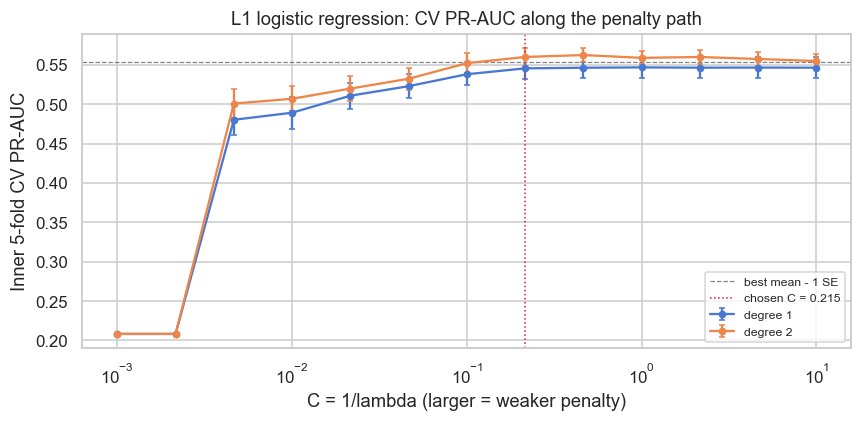

One-SE pick (degree, C): (2, 0.21544346900318823)
Final (degree, C) after the 5-predictor rule: (2, 0.21544346900318823)
Nonzero terms: 26 of 77
Original predictors used: 11


In [2]:
lasso = OneSELassoLogit().fit(X, y)
res = lasso.cv_results_
best = res.loc[res['mean'].idxmax()]

fig, ax = plt.subplots(figsize=(8, 4))
for d, g in res.groupby('degree'):
    ax.errorbar(g['C'], g['mean'], yerr=g['se'], marker='o', ms=4, capsize=2,
                label=f'degree {d}')
ax.axhline(best['mean'] - best['se'], color='grey', ls='--', lw=0.8,
           label='best mean - 1 SE')
ax.axvline(lasso.C_, color='crimson', ls=':', lw=1, label=f'chosen C = {lasso.C_:.3g}')
ax.set_xscale('log')
ax.set_xlabel('C = 1/lambda (larger = weaker penalty)')
ax.set_ylabel('Inner 5-fold CV PR-AUC')
ax.set_title('L1 logistic regression: CV PR-AUC along the penalty path')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

n_terms = int((lasso.pipeline_.named_steps['model'].coef_ != 0).sum())
n_possible = lasso.pipeline_.named_steps['poly'].n_output_features_
print('One-SE pick (degree, C):', lasso.one_se_pick_)
print('Final (degree, C) after the 5-predictor rule:', (lasso.degree_, lasso.C_))
print(f'Nonzero terms: {n_terms} of {n_possible}')
print('Original predictors used:', len(lasso.predictors_used_))

In [3]:
poly = lasso.pipeline_.named_steps['poly']
coef = pd.Series(lasso.pipeline_.named_steps['model'].coef_.ravel(),
                 index=poly.get_feature_names_out(X.columns))
nonzero = coef[coef != 0].sort_values(key=np.abs, ascending=False)
print('Largest standardised coefficients (log-odds per SD):')
nonzero.head(15).round(3)

Largest standardised coefficients (log-odds per SD):


free sulfur dioxide alcohol                 0.987
citric acid^2                              -0.817
density                                    -0.766
free sulfur dioxide log sulphates           0.516
total sulfur dioxide^2                     -0.468
free sulfur dioxide total sulfur dioxide   -0.438
pH alcohol                                  0.426
citric acid log residual sugar              0.364
free sulfur dioxide^2                      -0.285
log chlorides pH                           -0.274
citric acid log sulphates                  -0.274
citric acid free sulfur dioxide             0.257
fixed acidity log residual sugar            0.215
citric acid pH                              0.210
density log sulphates                       0.200
dtype: float64

## Cross-validate every candidate on the same 10 folds

For each fold we fit a fresh copy of the pipeline on 9 folds and score the held-out fold. We store the out-of-fold probabilities for the ROC and PR plots and for the threshold analysis in notebook 04.

In [4]:
def fold_metrics(y_true, prob):
    out = {'PR-AUC': average_precision_score(y_true, prob),
           'ROC-AUC': roc_auc_score(y_true, prob)}
    for t in (0.5, T_STAR):
        tn, fp, fn, tp = confusion_matrix(y_true, prob >= t, labels=[0, 1]).ravel()
        out[f'Sensitivity @{t:g}'] = tp / (tp + fn)
        out[f'Specificity @{t:g}'] = tn / (tn + fp)
    out[f'Cost/wine @{T_STAR:g}'] = expected_cost(y_true, prob, T_STAR, C_FN_BASE)
    return out

rows, lasso_folds = [], []
oof = pd.DataFrame({'y': y.values, 'fold': -1}, index=X.index)

with warnings.catch_warnings():
    warnings.simplefilter('ignore', category=RuntimeWarning)
    for name, model in candidate_models().items():
        for k, (tr, va) in enumerate(cv.split(X, y)):
            m = clone(model).fit(X.iloc[tr], y.iloc[tr])
            prob = m.predict_proba(X.iloc[va])[:, 1]
            oof.iloc[va, oof.columns.get_loc('fold')] = k
            oof.loc[X.index[va], name] = prob
            if isinstance(m, OneSELassoLogit):
                n = int((m.pipeline_.named_steps['model'].coef_ != 0).sum())
                lasso_folds.append({'fold': k, 'degree': m.degree_, 'C': m.C_,
                                    'terms': n, 'predictors': len(m.predictors_used_)})
            else:
                n = X.shape[1]
            rows.append({'model': name, 'fold': k, 'terms': n,
                         **fold_metrics(y.iloc[va].values, prob)})

folds = pd.DataFrame(rows)
print('done:', folds['model'].nunique(), 'models x', folds['fold'].nunique(), 'folds')

done: 4 models x 10 folds


### Stability of the L1 tuning across outer folds
If the inner CV picks very different specifications on different folds, the chosen degree and penalty are not well determined by the data.

In [5]:
pd.DataFrame(lasso_folds).round(4)

,fold,degree,C,terms,predictors
0,0,1,0.4642,11,11
1,1,2,0.1000,18,11
2,2,2,0.2154,25,11
3,3,1,0.1000,10,10
4,4,2,0.2154,28,11
5,5,2,0.2154,26,11
6,6,2,0.1000,18,11
7,7,2,0.1000,21,11
8,8,2,0.4642,38,11
9,9,2,0.2154,25,11


## Comparison table
Mean across the 10 folds ± SE (SD of the fold scores / $\sqrt{10}$).

In [6]:
metrics = [c for c in folds.columns if c not in ('model', 'fold', 'terms')]
g = folds.groupby('model', sort=False)
mean, se = g[metrics].mean(), g[metrics].std() / np.sqrt(10)

table = mean.round(3).astype(str) + ' ± ' + se.round(3).astype(str)
table.insert(0, 'terms (median)', g['terms'].median().astype(int))
table

,terms (median),PR-AUC,ROC-AUC,Sensitivity @0.5,Specificity @0.5,Sensitivity @0.25,Specificity @0.25,Cost/wine @0.25
model,,,,,,,,
Logistic (all 11),11,0.554 ± 0.024,0.819 ± 0.01,0.324 ± 0.018,0.939 ± 0.008,0.72 ± 0.017,0.779 ± 0.011,0.35 ± 0.014
L1 logistic (CV-tuned),23,0.561 ± 0.026,0.824 ± 0.01,0.327 ± 0.018,0.947 ± 0.007,0.73 ± 0.011,0.778 ± 0.01,0.345 ± 0.011
LDA,11,0.555 ± 0.024,0.815 ± 0.01,0.364 ± 0.012,0.932 ± 0.006,0.705 ± 0.015,0.776 ± 0.011,0.362 ± 0.014
Gaussian NB,11,0.524 ± 0.022,0.797 ± 0.011,0.677 ± 0.012,0.783 ± 0.008,0.789 ± 0.016,0.681 ± 0.009,0.384 ± 0.014


## ROC and PR curves (pooled out-of-fold probabilities)

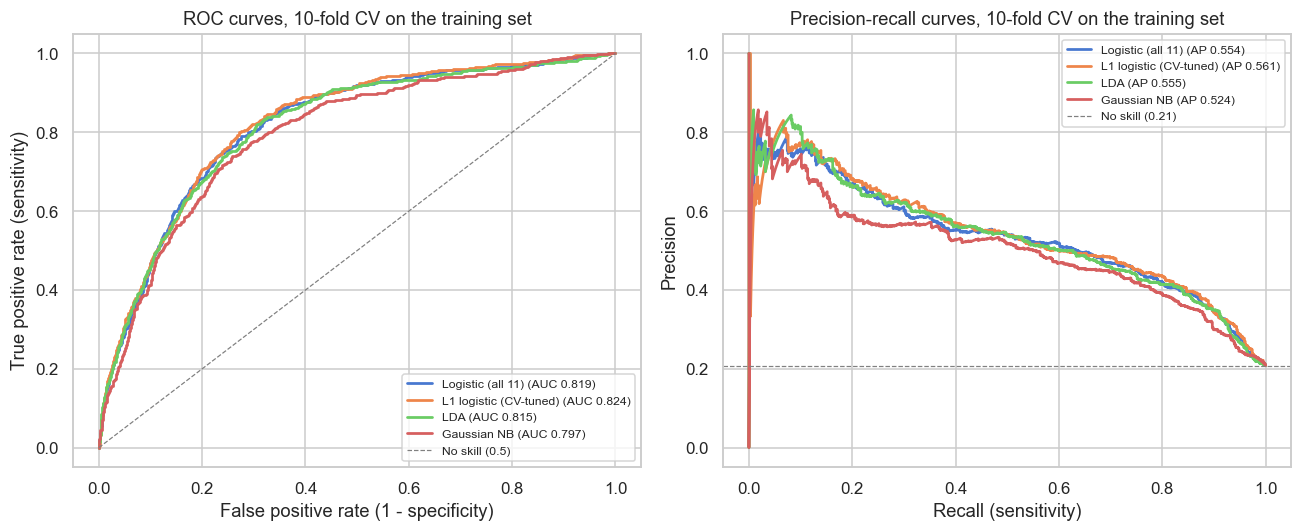

In [7]:
names = list(candidate_models())
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for name in names:
    fpr, tpr, _ = roc_curve(oof['y'], oof[name])
    axes[0].plot(fpr, tpr, lw=1.8,
                 label=f"{name} (AUC {mean.loc[name, 'ROC-AUC']:.3f})")
    prec, rec, _ = precision_recall_curve(oof['y'], oof[name])
    axes[1].plot(rec, prec, lw=1.8,
                 label=f"{name} (AP {mean.loc[name, 'PR-AUC']:.3f})")

axes[0].plot([0, 1], [0, 1], color='grey', ls='--', lw=0.8, label='No skill (0.5)')
axes[0].set(xlabel='False positive rate (1 - specificity)',
            ylabel='True positive rate (sensitivity)',
            title='ROC curves, 10-fold CV on the training set')
axes[1].axhline(y.mean(), color='grey', ls='--', lw=0.8,
                label=f'No skill ({y.mean():.2f})')
axes[1].set(xlabel='Recall (sensitivity)', ylabel='Precision',
            title='Precision-recall curves, 10-fold CV on the training set')
for ax in axes:
    ax.legend(fontsize=8, loc='lower right' if ax is axes[0] else 'upper right')
plt.tight_layout()
plt.show()

## Confusion matrices (pooled out-of-fold predictions)
Top row: default threshold 0.5. Bottom row: the base-case cost threshold $t^* = 0.25$.

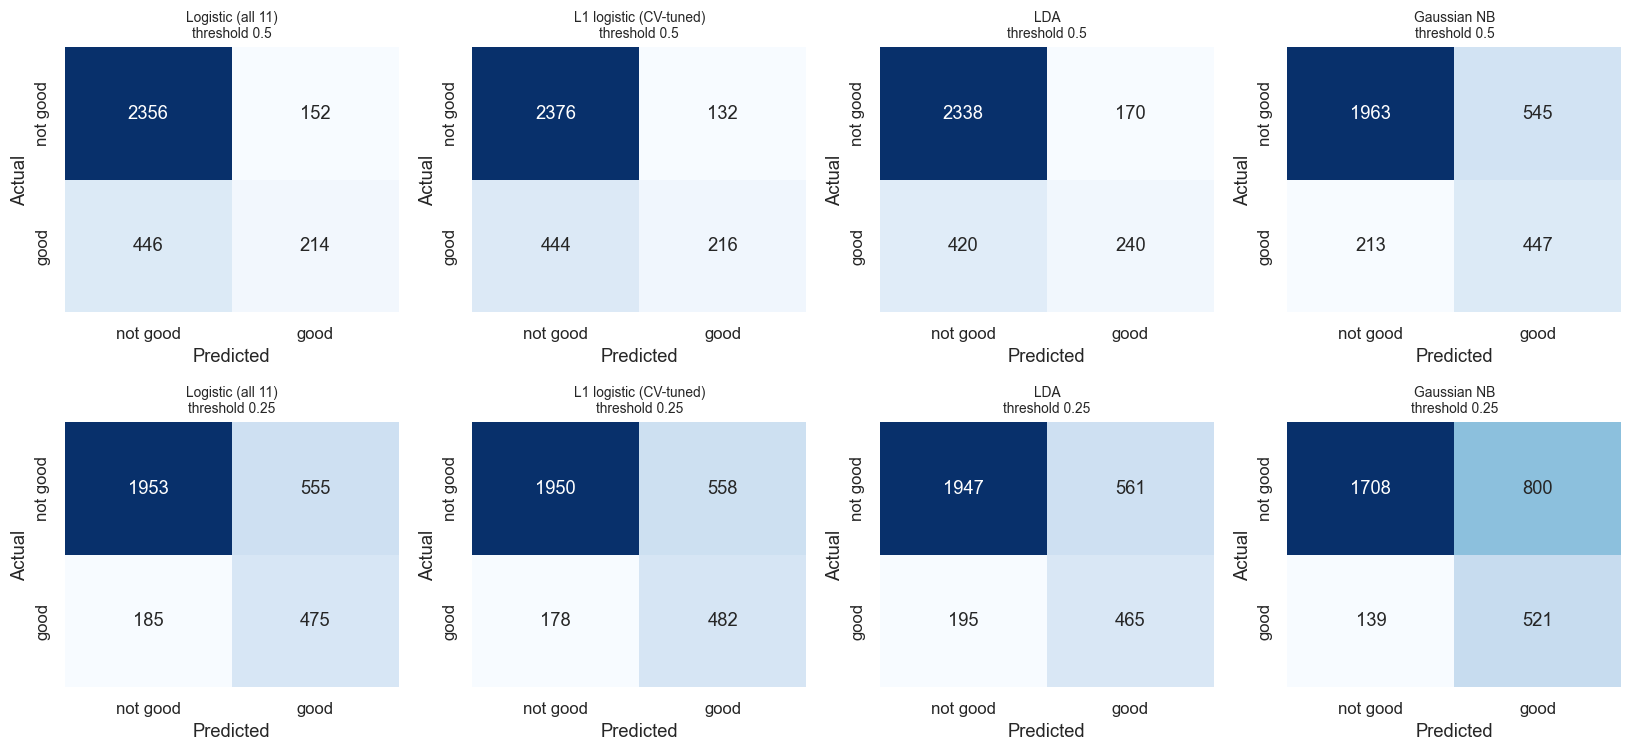

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(15, 7))
for r, t in enumerate((0.5, T_STAR)):
    for c, name in enumerate(names):
        cm = confusion_matrix(oof['y'], oof[name] >= t)
        sns.heatmap(cm, annot=True, fmt='d', cbar=False, cmap='Blues', ax=axes[r, c],
                    xticklabels=['not good', 'good'], yticklabels=['not good', 'good'])
        axes[r, c].set_title(f'{name}\nthreshold {t:g}', fontsize=9)
        axes[r, c].set_xlabel('Predicted')
        axes[r, c].set_ylabel('Actual')
plt.tight_layout()
plt.show()

## Apply the selection rule

In [9]:
summary = pd.DataFrame({
    'PR-AUC mean': mean['PR-AUC'],
    'PR-AUC SE': se['PR-AUC'],
    'terms': g['terms'].median(),
    'cost mean': mean[f'Cost/wine @{T_STAR:g}'],
})
top = summary['PR-AUC mean'].idxmax()
cutoff = summary.loc[top, 'PR-AUC mean'] - summary.loc[top, 'PR-AUC SE']
summary['within 1 SE of best'] = summary['PR-AUC mean'] >= cutoff

eligible = summary[summary['within 1 SE of best']].sort_values(['terms', 'cost mean'])
winner = eligible.index[0]

print(f'Best mean PR-AUC: {top} ({summary.loc[top, "PR-AUC mean"]:.3f}); one-SE cut-off {cutoff:.3f}')
print('Selected model:', winner)
summary.round(4)

Best mean PR-AUC: L1 logistic (CV-tuned) (0.561); one-SE cut-off 0.535
Selected model: Logistic (all 11)


,PR-AUC mean,PR-AUC SE,terms,cost mean,within 1 SE of best
model,,,,,
Logistic (all 11),0.5538,0.0241,11.0,0.3504,True
L1 logistic (CV-tuned),0.5608,0.0255,23.0,0.3447,True
LDA,0.5548,0.0237,11.0,0.3617,True
Gaussian NB,0.5242,0.0223,11.0,0.3841,False


## Save the frozen specification and the CV results

The winner is refit on the full training set (workflow step 6) in notebook 05, immediately before the single test-set audit, using exactly the specification saved here.

In [10]:
spec = {'name': winner,
        'cv_pr_auc_mean': float(summary.loc[winner, 'PR-AUC mean']),
        'cv_pr_auc_se': float(summary.loc[winner, 'PR-AUC SE']),
        'cv_roc_auc_mean': float(mean.loc[winner, 'ROC-AUC']),
        'cv_roc_auc_se': float(se.loc[winner, 'ROC-AUC'])}
if winner == 'L1 logistic (CV-tuned)':
    spec.update(degree=lasso.degree_, C=lasso.C_, predictors_used=lasso.predictors_used_)

with open('results/selected_model.json', 'w') as f:
    json.dump(spec, f, indent=2)
folds.to_csv('results/cv_fold_scores.csv', index=False)
oof.to_csv('results/oof_probabilities.csv')
spec

{'name': 'Logistic (all 11)',
 'cv_pr_auc_mean': 0.5537799042779806,
 'cv_pr_auc_se': 0.024149965517530736,
 'cv_roc_auc_mean': 0.8189351201255584,
 'cv_roc_auc_se': 0.010283168728452348}